# 01 · Análise exploratória — qualidade de vinhos
Tech Challenge Fase 2. **Pergunta central:** o que distingue vinhos de alta qualidade (`quality ≥ 7`) dos demais?
Todas as figuras são salvas em `results/figures/`. Conclusões abaixo são geradas a partir dos dados.
> Correlação/associação **não** é causalidade. Aqui descrevemos o que *aparece junto*, não o que *causa*.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":      # funciona rodando de notebooks/ ou da raiz do repositório
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src import config, eda
from src.preprocessing import carregar_dados, criar_alvo, NOMES_PT

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
CAMINHO = config.resolve_data_path()
print("BASE USADA:", CAMINHO.name, "" if config.is_official(CAMINHO) else
      f"  <-- ATENÇÃO: não é a base oficial ({config.OFFICIAL_DATASET}); execução de ENSAIO")
df = carregar_dados(CAMINHO)
config.ensure_dirs()

BASE USADA: WineQT.csv 


## 1. Estrutura, tipos, nulos e duplicatas

In [2]:
resumo = eda.resumo_estrutural(df)
display(pd.Series(resumo, name="valor").to_frame())
display(df.dtypes.to_frame("tipo").T)
display(df.describe().T.round(3))

,valor
linhas,1143.000000
colunas,12.000000
nulos_total,0.000000
duplicatas,125.000000
pct_duplicatas,0.109361


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality
tipo,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64


,count,mean,std,min,25%,50%,75%,max
fixed_acidity,1143.0,8.311,1.748,4.600,7.100,7.900,9.100,15.900
volatile_acidity,1143.0,0.531,0.180,0.120,0.392,0.520,0.640,1.580
citric_acid,1143.0,0.268,0.197,0.000,0.090,0.250,0.420,1.000
residual_sugar,1143.0,2.532,1.356,0.900,1.900,2.200,2.600,15.500
chlorides,1143.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free_sulfur_dioxide,1143.0,15.615,10.250,1.000,7.000,13.000,21.000,68.000
total_sulfur_dioxide,1143.0,45.915,32.782,6.000,21.000,37.000,61.000,289.000
density,1143.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
ph,1143.0,3.311,0.157,2.740,3.205,3.310,3.400,4.010
sulphates,1143.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


## 2. Variável-alvo: nota original e classe binária (corte `quality ≥ 7`)

,n,%
quality,,
3,6,0.52
4,33,2.89
5,483,42.26
6,462,40.42
7,143,12.51
8,16,1.40


,n,%
quality,,
Baixa/média (<7),984,86.09
Alta (≥7),159,13.91


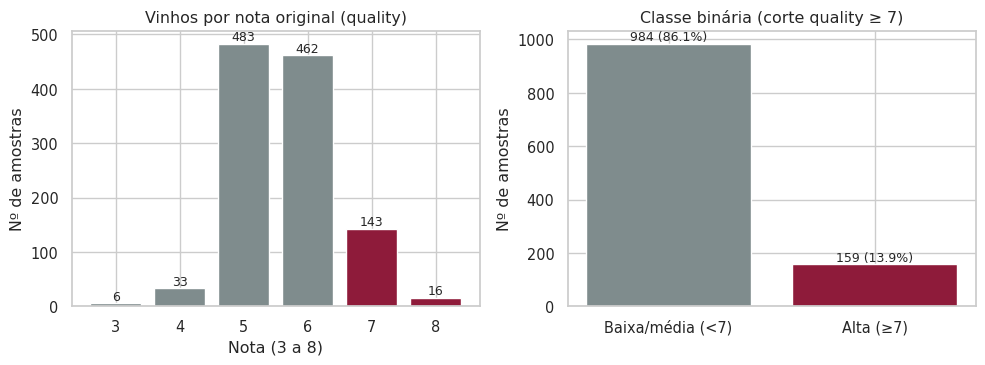

**Desbalanceamento:** 159 vinhos de alta qualidade (13.9%). Um classificador que sempre responde 'baixa/média' teria acurácia de 86.1% — por isso a acurácia não é a métrica principal.

In [3]:
por_nota, binaria, fig = eda.distribuicao_alvo(df)
display(por_nota); display(binaria); plt.show()
n_alta = int((df.quality >= 7).sum())
display(Markdown(f"**Desbalanceamento:** {n_alta} vinhos de alta qualidade ({n_alta/len(df):.1%}). "
  f"Um classificador que sempre responde 'baixa/média' teria acurácia de {1-n_alta/len(df):.1%} — "
  "por isso a acurácia não é a métrica principal."))

## 3. Distribuições das variáveis
Assimetria (*skewness*) alta indica cauda longa à direita — relevante para modelos lineares (ver notebook 02).

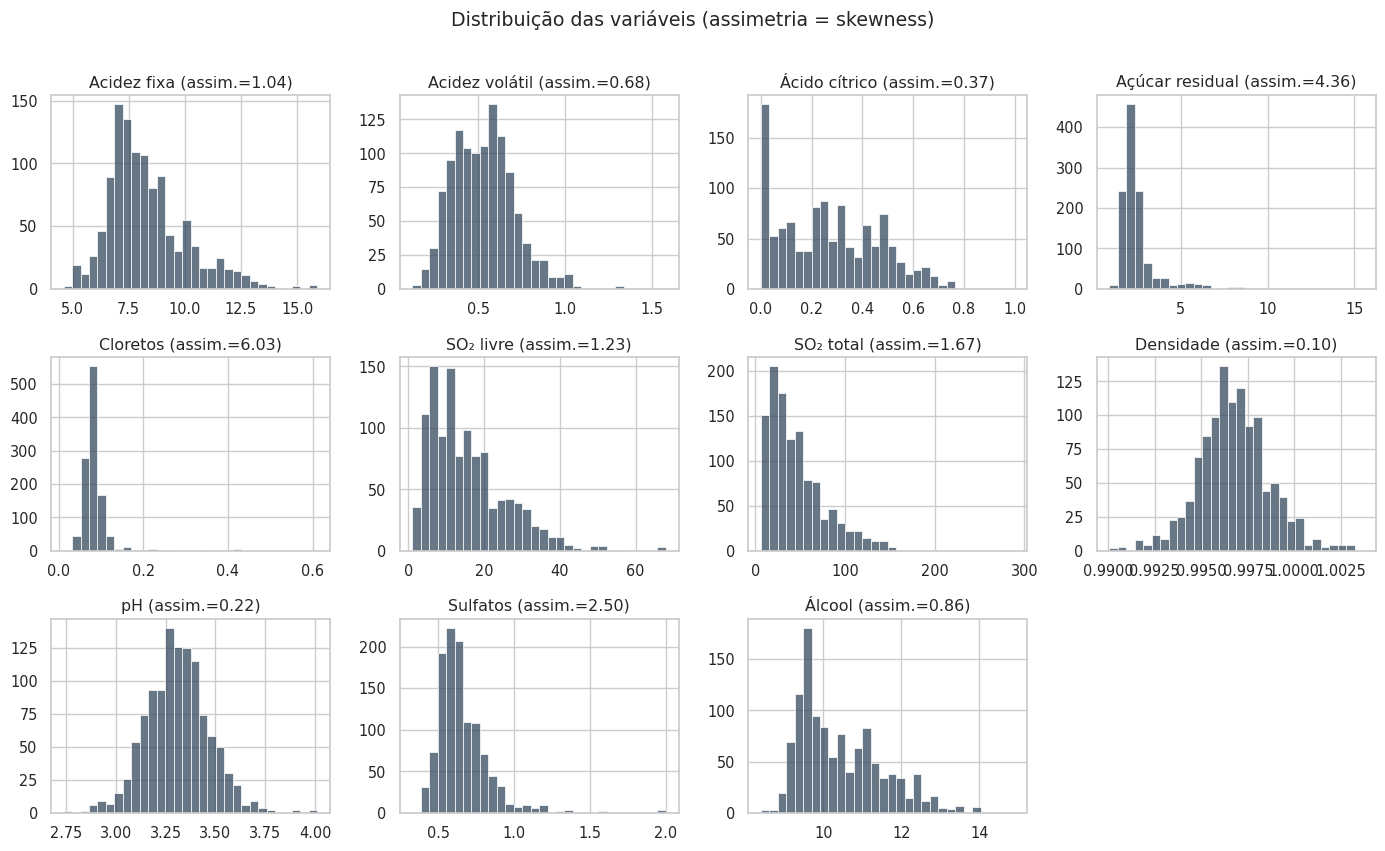

In [4]:
eda.histogramas(df); plt.show()

## 4. Variáveis × classe (substitui os gráficos de linha da média por nota)
**Por que mudar:** gráficos de linha ligam *médias* de variáveis em escalas muito diferentes (ex.: SO₂ em dezenas e cloretos em centésimos) e
sugerem uma tendência contínua que as poucas amostras das notas extremas (3 e 8) não sustentam. Boxplots por classe mostram mediana, dispersão e sobreposição.

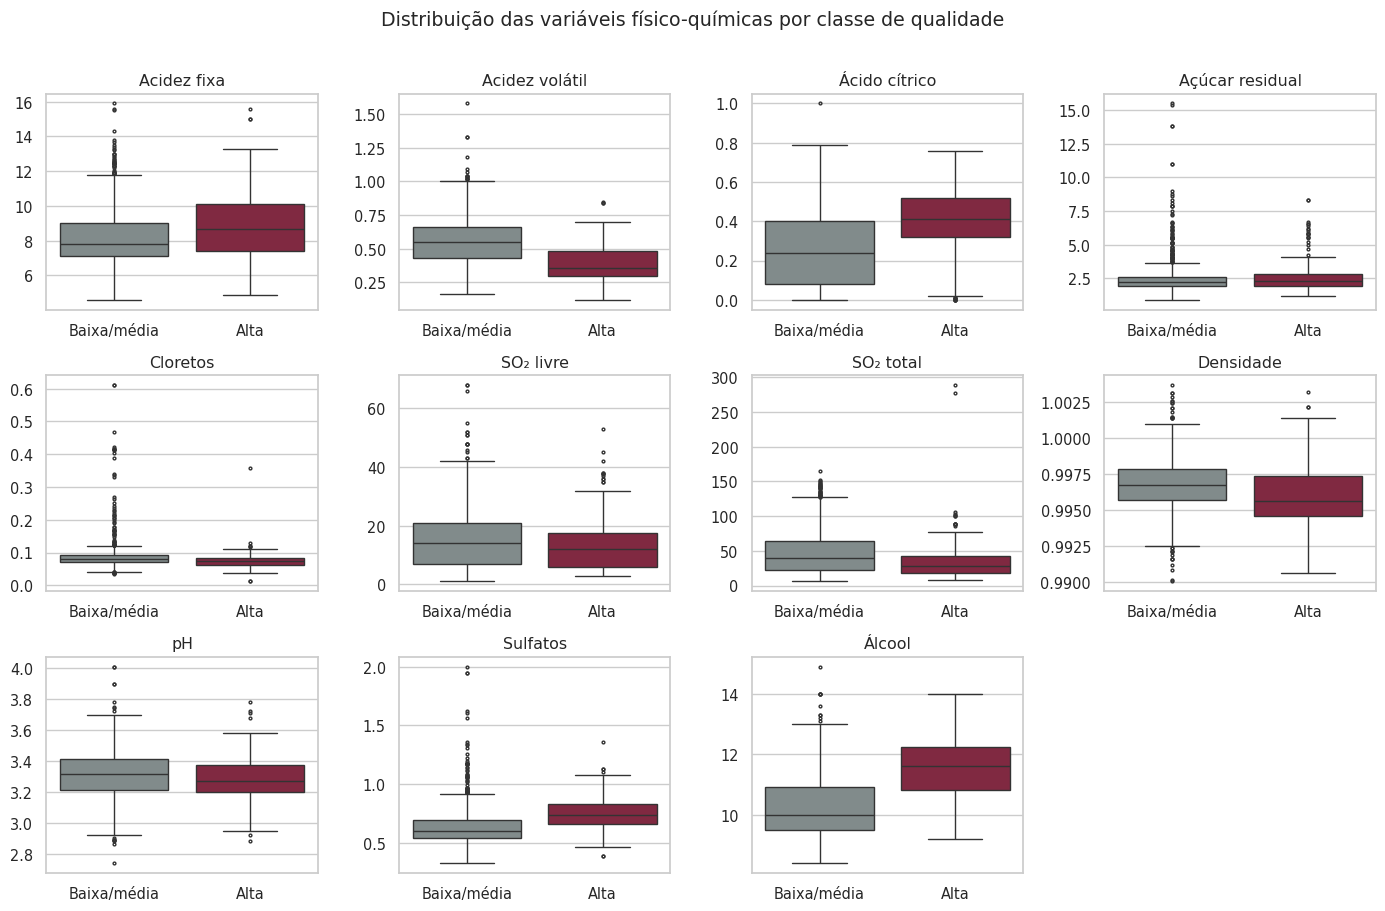

,mediana_baixa_media,mediana_alta,dif_medianas,cliffs_delta,p_valor
variavel,,,,,
alcohol,10.000,11.600,1.600,0.638,0.000
volatile_acidity,0.550,0.360,-0.190,-0.544,0.000
sulphates,0.600,0.740,0.140,0.485,0.000
citric_acid,0.240,0.410,0.170,0.410,0.000
chlorides,0.080,0.073,-0.007,-0.294,0.000
density,0.997,0.996,-0.001,-0.256,0.000
total_sulfur_dioxide,39.000,28.000,-11.000,-0.243,0.000
fixed_acidity,7.800,8.700,0.900,0.204,0.000
ph,3.315,3.270,-0.045,-0.134,0.006


In [5]:
eda.boxplots_por_classe(df); plt.show()
tab = eda.tabela_classes(df)
display(tab.round(3))

In [6]:
top = tab.head(3)
txt = "; ".join(f"**{NOMES_PT.get(v, v)}** (mediana {r.mediana_alta:.3g} na alta vs {r.mediana_baixa_media:.3g} na baixa/média, Cliff's δ={r.cliffs_delta:.2f})" for v, r in top.iterrows())
display(Markdown("**Maiores diferenças entre classes (por tamanho de efeito):** " + txt +
  ".  \n*Interpretação:* são **associações**. Mann-Whitney sem correção para 11 testes — leia os p-valores como descritivos."))

**Maiores diferenças entre classes (por tamanho de efeito):** **Álcool** (mediana 11.6 na alta vs 10 na baixa/média, Cliff's δ=0.64); **Acidez volátil** (mediana 0.36 na alta vs 0.55 na baixa/média, Cliff's δ=-0.54); **Sulfatos** (mediana 0.74 na alta vs 0.6 na baixa/média, Cliff's δ=0.49).  
*Interpretação:* são **associações**. Mann-Whitney sem correção para 11 testes — leia os p-valores como descritivos.

## 5. Correlações

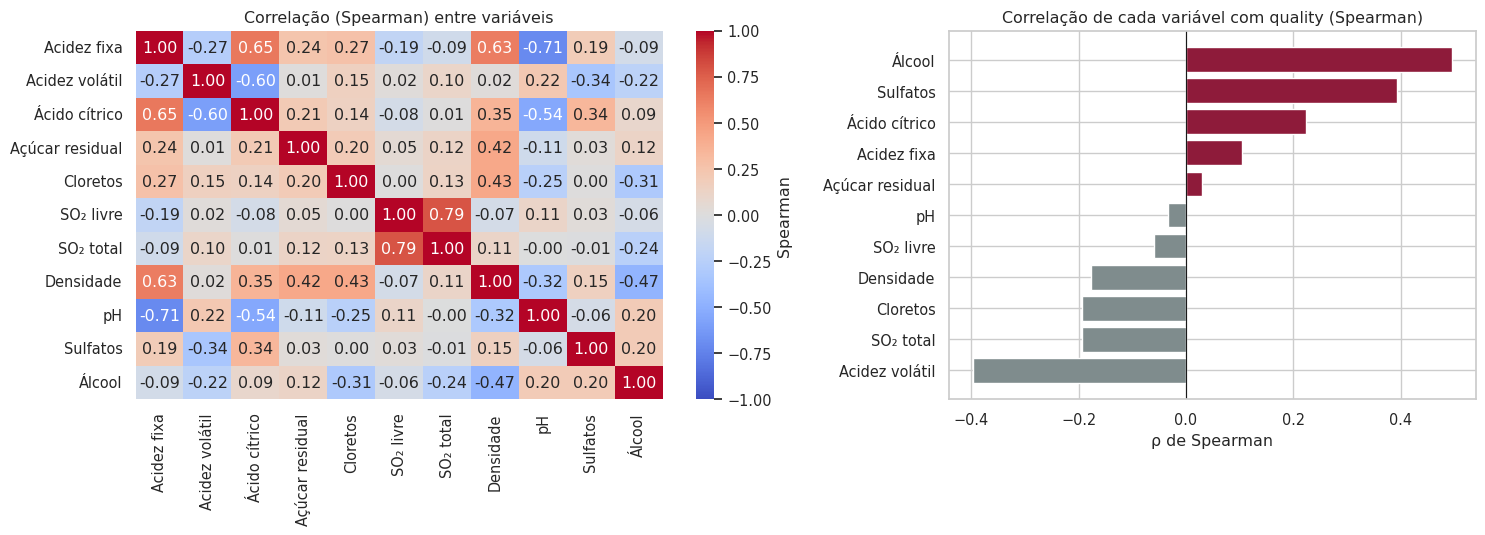

,spearman_quality,pontobiserial_classe_alta
alcohol,0.495,0.404
volatile_acidity,-0.398,-0.305
sulphates,0.394,0.208
citric_acid,0.223,0.251
total_sulfur_dioxide,-0.195,-0.113
chlorides,-0.194,-0.104
density,-0.177,-0.149
fixed_acidity,0.104,0.123
free_sulfur_dioxide,-0.059,-0.056
ph,-0.033,-0.073


**Pares de variáveis muito correlacionados (|ρ| ≥ 0,6)** — relevante para interpretar importâncias:

,var_a,var_b,spearman
4,free_sulfur_dioxide,total_sulfur_dioxide,0.79
2,fixed_acidity,ph,-0.71
0,fixed_acidity,citric_acid,0.65
1,fixed_acidity,density,0.63
3,volatile_acidity,citric_acid,-0.60


In [7]:
corr, com_alvo, fig = eda.correlacoes(df); plt.show()
display(com_alvo.round(3))
display(Markdown("**Pares de variáveis muito correlacionados (|ρ| ≥ 0,6)** — relevante para interpretar importâncias:"))
display(eda.pares_muito_correlacionados(corr).round(2))

### Justificativa de cada correlação forte (exigência da especificação)
`tipo`: **mecânica** = identidade/definição; **química** = relação físico-química conhecida; **hipótese** = plausível, *não* comprovada pelos dados.

In [8]:
pd.set_option("display.max_colwidth", 120)
just = eda.justificar_correlacoes(corr, limite=0.5)
just.to_csv(config.RESULTS_DIR / "correlacoes_justificadas.csv", index=False)
display(just)

,var_a,var_b,spearman,tipo,justificativa
0,SO₂ livre,SO₂ total,0.79,mecânica,SO₂ total = SO₂ livre + ligado; a parte livre compõe o total.
1,Acidez fixa,pH,-0.71,química,O pH mede acidez: mais ácidos fixos → pH menor (relação inversa esperada).
2,Acidez fixa,Ácido cítrico,0.65,mecânica,O ácido cítrico é um dos ácidos que compõem a acidez fixa.
3,Acidez fixa,Densidade,0.63,química,Ácidos fixos dissolvidos (ex.: tartárico) aumentam a massa por volume → densidade maior.
4,Acidez volátil,Ácido cítrico,-0.60,hipótese,Associação inversa; pode refletir processos de fermentação/conservação distintos. Não comprovado aqui.
5,Ácido cítrico,pH,-0.54,química,O ácido cítrico é um ácido; mais cítrico → pH menor.


## 6. Outliers e valores inconsistentes
Outliers por IQR são **candidatos**; em química de vinho valores altos de açúcar e cloretos são plausíveis. **Não removemos outliers**
(sem evidência de erro de medição), e usamos transformação e modelos robustos.

In [9]:
display(eda.outliers_iqr(df))
display(eda.inconsistencias(df))

,n_outliers,pct,assimetria
residual_sugar,110,9.62,4.36
chlorides,77,6.74,6.03
fixed_acidity,44,3.85,1.04
sulphates,43,3.76,2.50
total_sulfur_dioxide,40,3.50,1.67
density,36,3.15,0.10
ph,20,1.75,0.22
free_sulfur_dioxide,18,1.57,1.23
volatile_acidity,14,1.22,0.68
alcohol,12,1.05,0.86


,n_linhas
valores negativos (qualquer feature),0
SO₂ livre > SO₂ total,0
"pH fora de [2,5; 4,5]",0
teor alcoólico fora de [5; 17] %,0
"densidade fora de [0,98; 1,01]",0
"ácido cítrico = 0 (plausível, só informativo)",99
nota fora de 0–10,0


## 7. Síntese (gerada automaticamente)

In [10]:
top_c = com_alvo.head(3)
display(Markdown("**Fatos observados:** " +
  f"{len(df)} linhas, {resumo['nulos_total']} nulos, {resumo['duplicatas']} duplicatas exatas ({resumo['pct_duplicatas']:.1%}); " +
  "maiores associações com a nota: " + ", ".join(f"{NOMES_PT.get(v, v)} (ρ={r.spearman_quality:.2f})" for v, r in top_c.iterrows()) + ".  \n" +
  "**Cautelas:** associação ≠ causalidade; variáveis correlacionadas entre si; classe alta é minoritária."))

**Fatos observados:** 1143 linhas, 0 nulos, 125 duplicatas exatas (10.9%); maiores associações com a nota: Álcool (ρ=0.50), Acidez volátil (ρ=-0.40), Sulfatos (ρ=0.39).  
**Cautelas:** associação ≠ causalidade; variáveis correlacionadas entre si; classe alta é minoritária.